# Inspect SAMap transfer outputs (post counts-fix refit)

Reads the finished `*_transferred.h5ad` objects — which already carry the coarse dec/fib transfer,
the fine subtype transfer (mouse→human), and pseudotime — and inspects them the way
`inspect_samap_transfer` did: confusion matrices, the fibroblast→decidual bleed, and spatial
independent-vs-transferred panels. 

**Why read the objects, not the pkl:** the pipeline already computed every transfer into these
h5ads. Reading them is fast, needs no 7 GB pkl load, and needs no samap/GLIBCXX. Any env with
scanpy/anndata works (`rsc_uv` is fine).

**These objects are from the corrected (raw-counts) refit** — so the numbers here supersede the
pre-fix run. Section 6 compares old vs new recall directly.

## Config + load

In [1]:
%matplotlib inline
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt

RESULTS = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/samap_transfer"
RUN = "secretory_x_1dpi_late_hmmer"          # or "secretory_x_1dpi_late_hmmer"

a = ad.read_h5ad(f"{RESULTS}/{RUN}_transferred.h5ad")
is_h = (a.obs["species"].astype(str) == "hs").values
is_m = (a.obs["species"].astype(str) == "mm").values
print(a.shape, "| human", int(is_h.sum()), "mouse", int(is_m.sum()))
print("obs:", [c for c in a.obs.columns if not c.startswith(("hs_","mm_","leiden"))])

(34228, 70299) | human 23441 mouse 10787
obs: ['batch', 'species', 'cell_type_independent', 'cell_type_transferred', 'transferred_frac_decidual', 'cell_subtype', 'cell_subtype_transferred', 'cell_subtype_transferred_frac', 'pseudotime', 'pseudotime_source']


## 1. Coarse transfer — independent vs transferred, per species

`cell_type_independent` = each cell's own-species coarse label. `cell_type_transferred` = the label
voted from the other species across the SAMap graph. Diagonal = agreement; the off-diagonal
**endometrial fibroblast → decidual** cell is the decidualization bleed the `fib_recall` numbers
summarize.

In [2]:
IND, TR = "cell_type_independent", "cell_type_transferred"
def confusion(mask, name):
    sub = a.obs[mask]
    ct = pd.crosstab(sub[IND].astype(str), sub[TR].astype(str))
    print(f"=== {name}  (n={mask.sum()}) ===")
    print(ct.to_string()); 
    for lab in ["decidual", "endometrial fibroblast"]:
        d = sub[IND].astype(str) == lab
        if d.sum():
            rec = float((sub[TR].astype(str)[d] == lab).mean())
            print(f"  {lab:22s} recall = {rec:.3f}  (n={int(d.sum())})")
    print()
confusion(is_h, "HUMAN  (own human labels vs voted-from-mouse)")
confusion(is_m, "MOUSE  (own mouse labels vs voted-from-human)")

=== HUMAN  (own human labels vs voted-from-mouse)  (n=23441) ===
cell_type_transferred   decidual  endometrial fibroblast  no cross-species neighbor
cell_type_independent                                                              
decidual                    4778                     772                          0
endometrial fibroblast      6784                   11099                          8
  decidual               recall = 0.861  (n=5550)
  endometrial fibroblast recall = 0.620  (n=17891)

=== MOUSE  (own mouse labels vs voted-from-human)  (n=10787) ===
cell_type_transferred   decidual  endometrial fibroblast  no cross-species neighbor
cell_type_independent                                                              
decidual                    3273                    2381                          0
endometrial fibroblast       188                    4944                          1
  decidual               recall = 0.579  (n=5654)
  endometrial fibroblast recall = 0.963  (n=51

## 2. Continuous decidual fraction — the signal behind the 0.5 threshold

`transferred_frac_decidual` is the connectivity-weighted fraction of cross-species neighbors that are
decidual (thresholded at 0.5 for the binary call). Its distribution shows how *confident* the
transfer is: bimodal (near 0 / near 1) = clean separation; piled at 0.5 = ambiguous alignment.

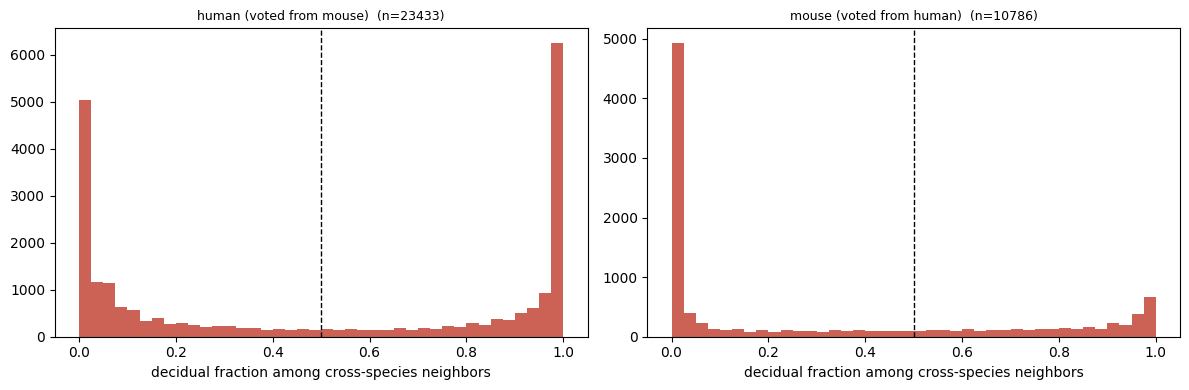

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k,(nm,m) in enumerate([("human (voted from mouse)",is_h),("mouse (voted from human)",is_m)]):
    v = a.obs["transferred_frac_decidual"].values[m]; v = v[np.isfinite(v)]
    ax[k].hist(v, bins=40, color="#c0392b", alpha=.8)
    ax[k].axvline(0.5, color="k", ls="--", lw=1)
    ax[k].set_title(f"{nm}  (n={len(v)})", fontsize=9)
    ax[k].set_xlabel("decidual fraction among cross-species neighbors")
plt.tight_layout(); plt.show()

## 3. Fine subtype transfer (mouse → human)

`cell_subtype_transferred` = which of the 9 mouse fine subtypes (dec1/2/3/decAp, eFib1/2/2i/3/P) each
**human** cell most resembles, with `cell_subtype_transferred_frac` as the winning-neighbor
confidence. This is what the coarse transfer can't tell you — the sub-state resolution.

In [4]:
ct = a.obs.loc[is_h, "cell_subtype_transferred"].astype(str)
ct = ct[ct.str.len() > 0]
print("human cells by transferred mouse subtype:")
print(ct.value_counts().to_string())
if "cell_subtype_transferred_frac" in a.obs:
    fr = a.obs.loc[is_h, "cell_subtype_transferred_frac"].astype(float)
    print(f"\nconfidence: median {fr.median():.2f}  |  frac >0.5: {(fr>0.5).mean():.2f}")

human cells by transferred mouse subtype:
cell_subtype_transferred
eFib2i    9596
dec2      7941
dec1      2991
eFib3     1459
eFib1      780
dec3       363
decAp      267
eFibP       36

confidence: median 0.80  |  frac >0.5: 0.92


## 4. Fine subtype on the joint UMAP — mouse native beside human transferred

Same palette both panels, so a color = the same mouse subtype. Left: mouse's own subtypes.
Right: those subtypes voted onto human. This is the fine transfer, visually.

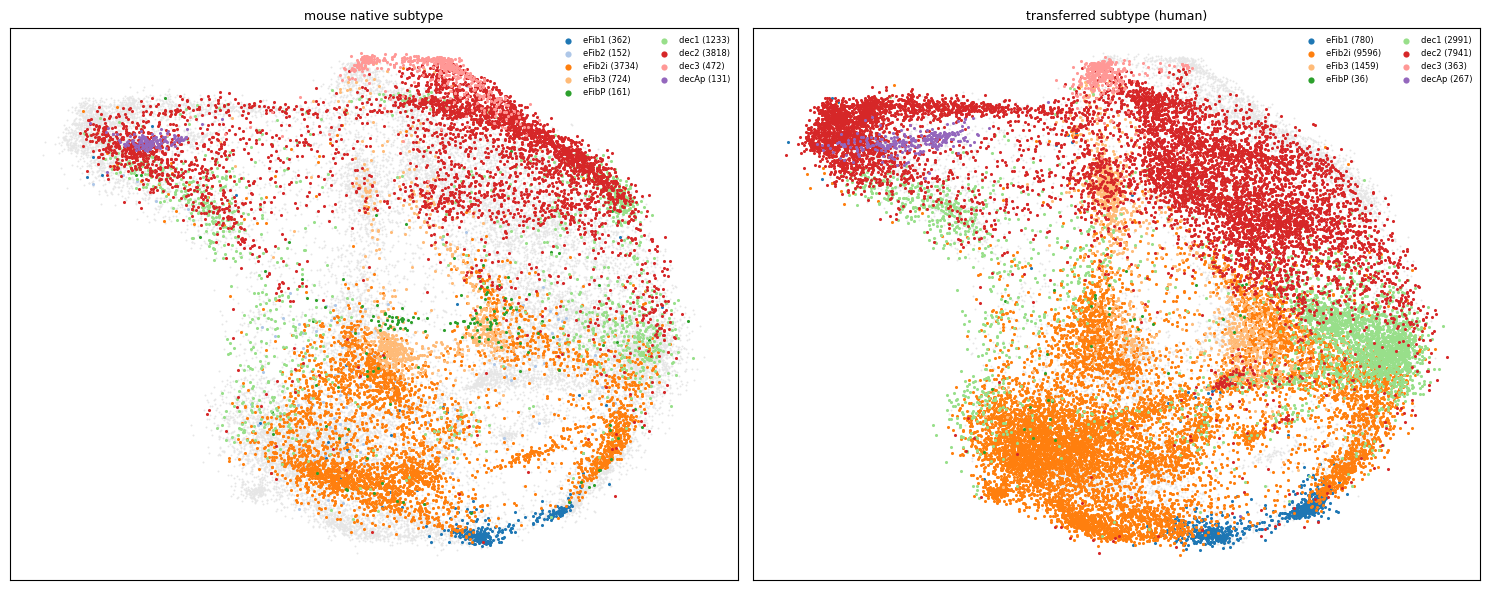

In [5]:
U = np.asarray(a.obsm["X_umap"])
SUBTYPES = ["eFib1","eFib2","eFib2i","eFib3","eFibP","dec1","dec2","dec3","decAp"]
COL = {s: plt.get_cmap("tab20").colors[i] for i,s in enumerate(SUBTYPES)}
def umap_sub(ax, values, mask, title):
    v = a.obs[values].astype(str).values
    ax.scatter(U[~mask,0], U[~mask,1], s=2, color="0.9", linewidths=0)
    for s in SUBTYPES:
        m = mask & (v == s)
        if m.sum(): ax.scatter(U[m,0], U[m,1], s=5, color=COL[s], label=f"{s} ({int(m.sum())})", linewidths=0)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=2, fontsize=6, frameon=False, ncol=2)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
umap_sub(ax[0], "cell_subtype", is_m, "mouse native subtype")
umap_sub(ax[1], "cell_subtype_transferred", is_h, "transferred subtype (human)")
plt.tight_layout(); plt.show()

## 5. Spatial — independent vs transferred, per species (coords are per-species)

The `inspect` notebook's key panel: does the TRANSFERRED decidual territory overlap the INDEPENDENT
decidual territory on the tissue? Overlap = faithful transfer; spatially random transferred vs
structured independent = a problem. `obsm['spatial']` is per-species (not co-registered), so we plot
each species in its own frame. Switch LABEL to inspect the fibroblast side.

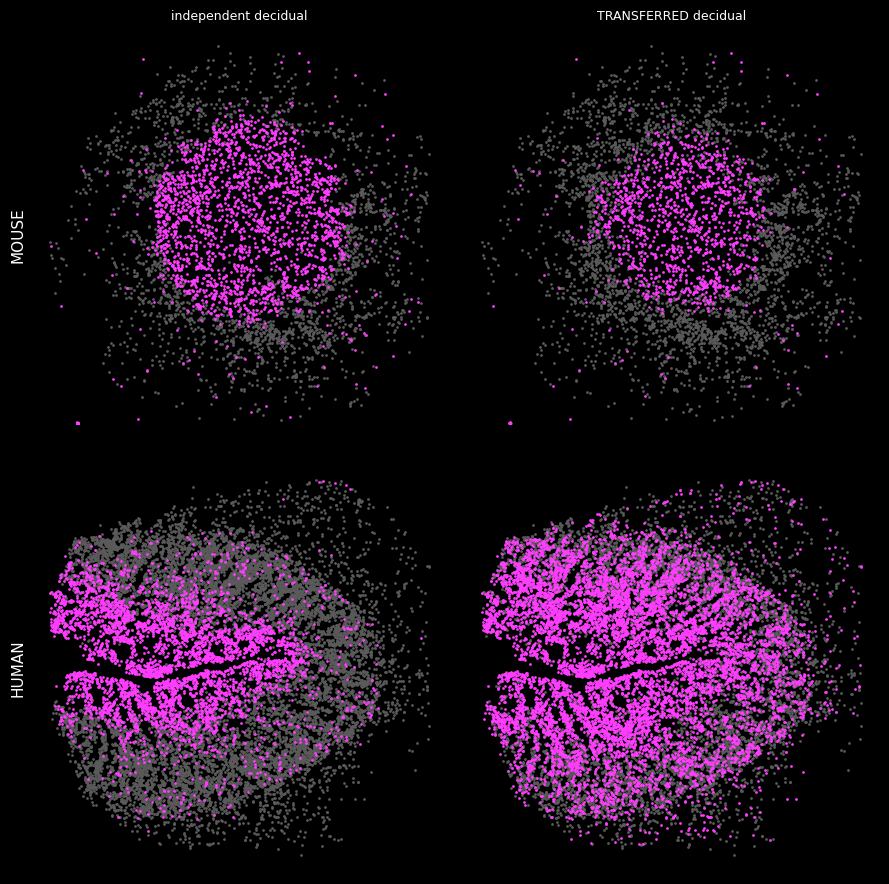

In [6]:
XY = np.asarray(a.obsm["spatial"])
LABEL = "decidual"                                  # "decidual" | "endometrial fibroblast"
PINK, GREY = "#FF3DFF", "#5a5a5a"
def panel(ax, smask, lmask, title):
    ax.set_facecolor("black")
    m = smask & np.isfinite(XY[:,0]) & np.isfinite(XY[:,1])
    ax.scatter(XY[m & ~lmask,0], XY[m & ~lmask,1], s=4, c=GREY, linewidths=0)
    ax.scatter(XY[m &  lmask,0], XY[m &  lmask,1], s=4, c=PINK, linewidths=0)
    ax.set_title(title, color="white", fontsize=9); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
ind = (a.obs[IND].astype(str) == LABEL).values
tr  = (a.obs[TR].astype(str)  == LABEL).values
fig, ax = plt.subplots(2, 2, figsize=(9, 9)); fig.patch.set_facecolor("black")
for r,(sm,nm) in enumerate([(is_m,"MOUSE"),(is_h,"HUMAN")]):
    panel(ax[r,0], sm, ind, f"independent {LABEL}" if r==0 else "")
    panel(ax[r,1], sm, tr,  f"TRANSFERRED {LABEL}" if r==0 else "")
    ax[r,0].set_ylabel(nm, color="white", fontsize=11)
plt.tight_layout(); plt.show()

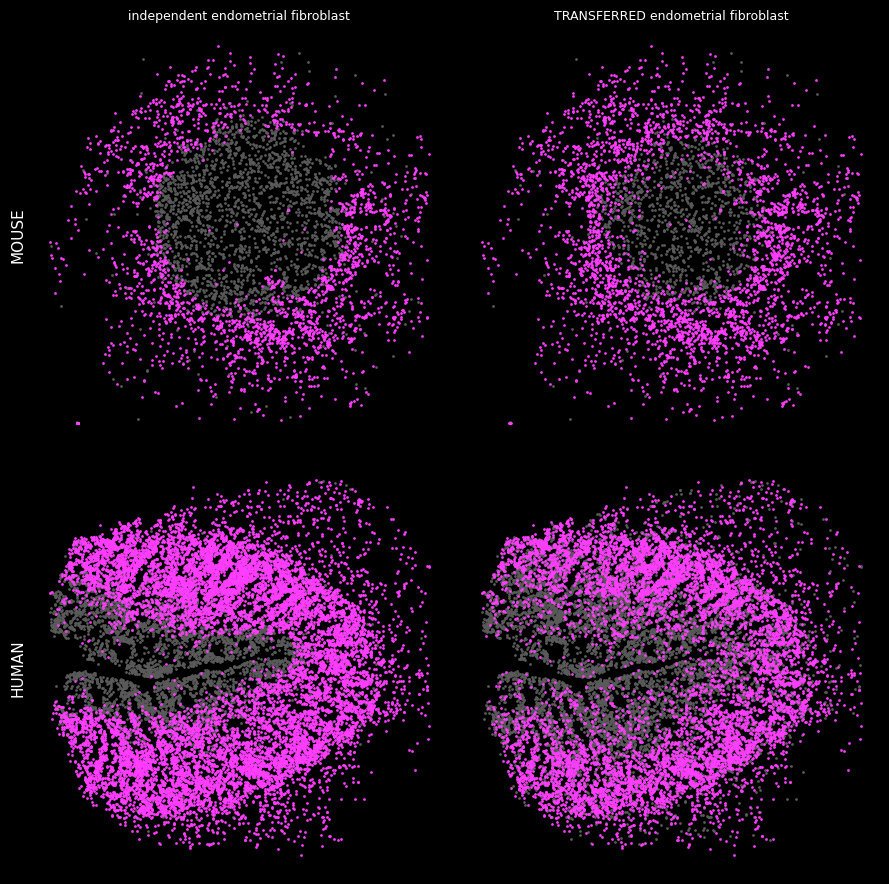

In [8]:
XY = np.asarray(a.obsm["spatial"])
LABEL = "endometrial fibroblast"                                  # "decidual" | "endometrial fibroblast"
PINK, GREY = "#FF3DFF", "#5a5a5a"
def panel(ax, smask, lmask, title):
    ax.set_facecolor("black")
    m = smask & np.isfinite(XY[:,0]) & np.isfinite(XY[:,1])
    ax.scatter(XY[m & ~lmask,0], XY[m & ~lmask,1], s=4, c=GREY, linewidths=0)
    ax.scatter(XY[m &  lmask,0], XY[m &  lmask,1], s=4, c=PINK, linewidths=0)
    ax.set_title(title, color="white", fontsize=9); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
ind = (a.obs[IND].astype(str) == LABEL).values
tr  = (a.obs[TR].astype(str)  == LABEL).values
fig, ax = plt.subplots(2, 2, figsize=(9, 9)); fig.patch.set_facecolor("black")
for r,(sm,nm) in enumerate([(is_m,"MOUSE"),(is_h,"HUMAN")]):
    panel(ax[r,0], sm, ind, f"independent {LABEL}" if r==0 else "")
    panel(ax[r,1], sm, tr,  f"TRANSFERRED {LABEL}" if r==0 else "")
    ax[r,0].set_ylabel(nm, color="white", fontsize=11)
plt.tight_layout(); plt.show()

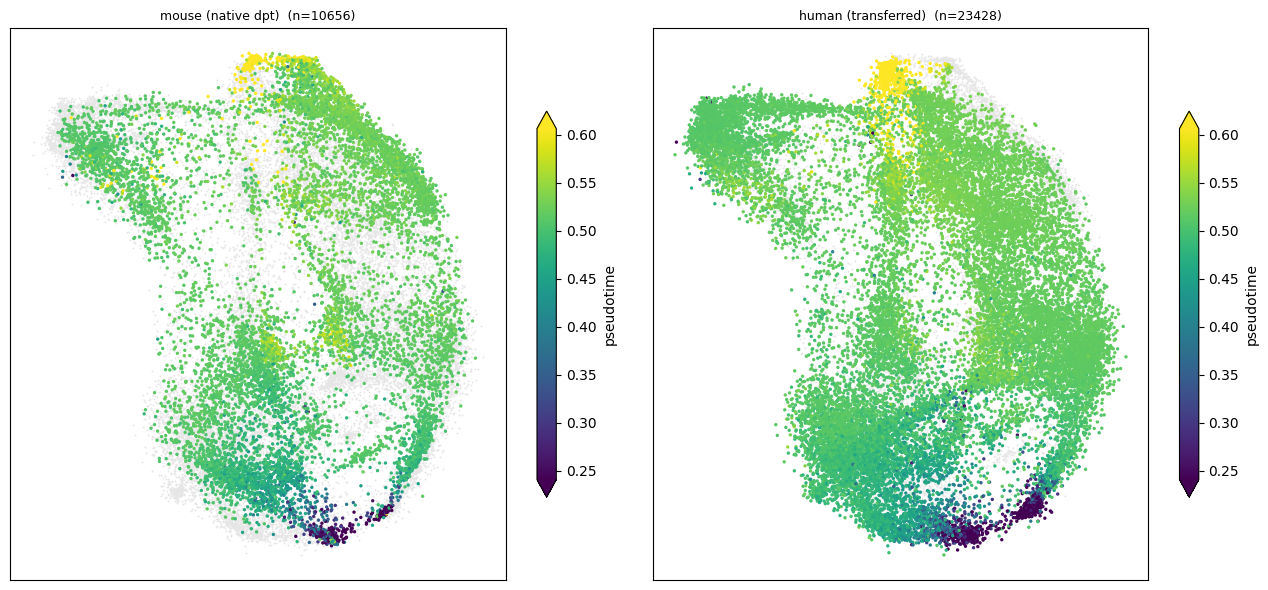

human transferred pseudotime by transferred subtype (low -> high):
                              mean    median  count
cell_subtype_transferred                           
eFib1                     0.233010  0.219217    780
eFib2i                    0.490370  0.498263   9596
eFibP                     0.512734  0.513371     36
decAp                     0.515481  0.511539    262
dec1                      0.518327  0.517288   2991
dec2                      0.523137  0.523339   7941
eFib3                     0.545310  0.533514   1459
dec3                      0.818878  0.843662    363


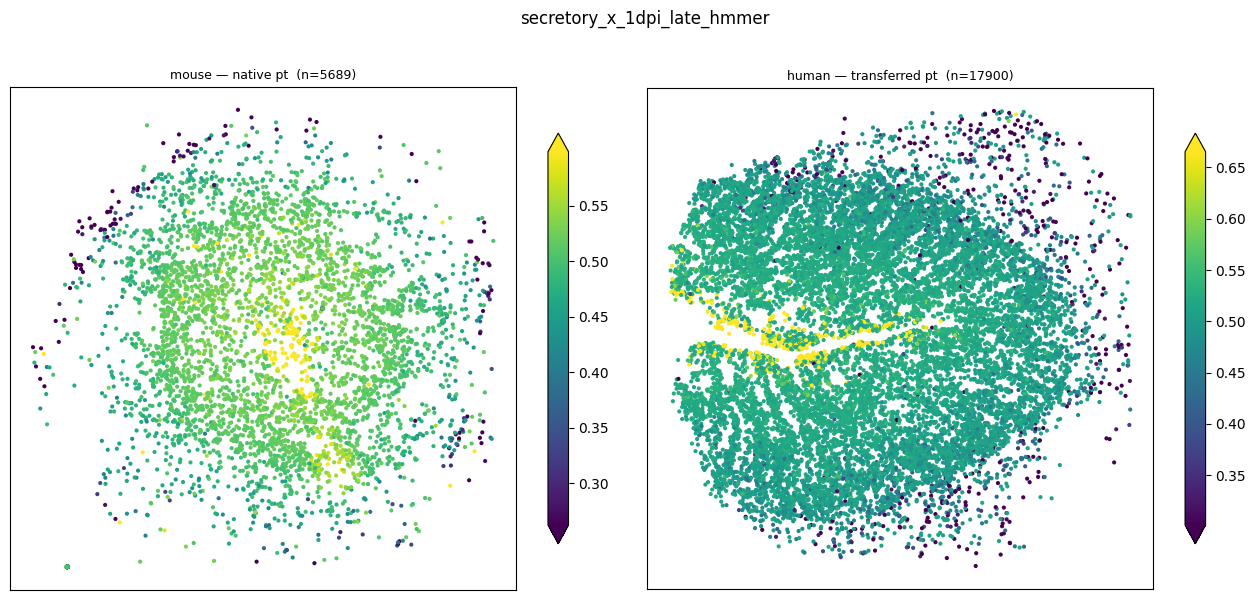

In [9]:
## 7. Pseudotime transfer — native (mouse) + transferred (human)
# `pseudotime` = mouse cells' native dpt + human cells' transferred value (weighted avg of mouse
# neighbors); `pseudotime_source` marks which. Shared p2–p98 scale across species, so a color means
# the same pseudotime value in both.

pt  = a.obs["pseudotime"].values.astype(float)
fin = np.isfinite(pt)
vmin, vmax = np.percentile(pt[fin], (2, 98))            # shared clip across both species

# --- joint UMAP: mouse native | human transferred, shared scale ---
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for k, (nm, m) in enumerate([("mouse (native dpt)", is_m), ("human (transferred)", is_h)]):
    keep = m & fin
    ax[k].scatter(U[~keep,0], U[~keep,1], s=2, color="0.9", linewidths=0, zorder=0)
    sc = ax[k].scatter(U[keep,0], U[keep,1], c=pt[keep], s=6, cmap="viridis",
                       vmin=vmin, vmax=vmax, linewidths=0)
    ax[k].set_title(f"{nm}  (n={int(keep.sum())})", fontsize=9)
    ax[k].set_xticks([]); ax[k].set_yticks([])
    plt.colorbar(sc, ax=ax[k], shrink=0.7, extend="both", label="pseudotime")
plt.tight_layout(); plt.show()

# --- orientation check: does transferred pt increase eFib -> dec on HUMAN? ---
hp = a.obs.loc[is_h].copy()
hp = hp[np.isfinite(hp["pseudotime"].astype(float))]
by_sub = (hp.groupby(hp["cell_subtype_transferred"].astype(str))["pseudotime"]
            .agg(["mean", "median", "count"]).sort_values("mean"))
print("human transferred pseudotime by transferred subtype (low -> high):")
print(by_sub.to_string())

# --- spatial: transferred pt on human tissue, native pt on mouse tissue ---
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5)); fig.patch.set_facecolor("white")
for k, (nm, m) in enumerate([("mouse — native pt", is_m), ("human — transferred pt", is_h)]):
    keep = m & np.isfinite(XY[:,0]) & np.isfinite(XY[:,1]) & fin
    ax[k].set_facecolor("white"); ax[k].set_aspect("equal"); ax[k].set_xticks([]); ax[k].set_yticks([])
    ax[k].set_title(f"{nm}  (n={int(keep.sum())})", fontsize=9)
    if keep.sum():
        vlo, vhi = np.percentile(pt[keep], (2, 98))
        s = ax[k].scatter(XY[keep,0], XY[keep,1], c=pt[keep], s=9, cmap="viridis",
                          vmin=vlo, vmax=vhi, linewidths=0)
        plt.colorbar(s, ax=ax[k], shrink=0.7, extend="both")
plt.suptitle(RUN); plt.tight_layout(); plt.show()

## 6. Old vs new recall — what the counts-fix changed

The refit on raw counts (vs the earlier double-normalized inputs) restored the full gene complement.
This compares the coarse-transfer recall from the stats JSONs: OLD = the pre-fix backup, NEW = this
run. Expect decidual recall to hold/rise and fibroblast recall to shift as the alignment sharpens.

In [7]:
import json, os
BK="/n/lab_storage/eddy_lab/users/nhilgert/samap_prenorm_fix_backup"
NEW="/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/tables/samap_transfer"
rows=[]
for run in ["menstrual_x_4dpi_hmmer","secretory_x_1dpi_late_hmmer"]:
    for tag,d in [("OLD",BK),("NEW",NEW)]:
        f=os.path.join(d,f"{run}_labelstain.json")
        if not os.path.exists(f): continue
        ta=json.load(open(f)).get("transfer_agreement",{})
        for sp in ("human","mouse"):
            s=ta.get(sp,{})
            rows.append(dict(run=run.replace("_hmmer",""), set=tag, species=sp,
                             agree=round(s.get("agreement",np.nan),3),
                             dec_recall=round(s.get("dec_recall",np.nan),3),
                             fib_recall=round(s.get("fib_recall",np.nan),3)))
df=pd.DataFrame(rows)
print(df.to_string(index=False))

                  run set species  agree  dec_recall  fib_recall
     menstrual_x_4dpi OLD   human  0.716       0.843       0.462
     menstrual_x_4dpi OLD   mouse  0.883       0.923       0.732
     menstrual_x_4dpi NEW   human  0.653       0.862       0.230
     menstrual_x_4dpi NEW   mouse  0.808       0.855       0.629
secretory_x_1dpi_late OLD   human  0.656       0.779       0.618
secretory_x_1dpi_late OLD   mouse  0.788       0.635       0.956
secretory_x_1dpi_late NEW   human  0.678       0.861       0.621
secretory_x_1dpi_late NEW   mouse  0.762       0.579       0.963
